# Tissue-specific expression in pig

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from upsetplot import UpSet
from upsetplot import from_indicators

## Read in regulatory features

- Rename fields
- Add gene id and length
- Keep only promoters and enhancers

In [2]:
pig_features = pd.read_csv("../../data/notebooks/Sus_scrofa.Sscrofa11.1.regulatory_features.v114.gff3.gz", sep="\t", skiprows=1, header=None, dtype = {0: str})
pig_features.columns = ['seqid', 'source', 'type', 'start', 'end', 'score', 'strand', 'phase', 'attributes']

In [3]:
pig_features['length'] = pig_features['end'] - pig_features['start'] + 1

def extract_attribute(attributes, key):
    pairs = dict(item.split("=") for item in attributes.split(";"))
    return pairs.get(key, "")
 
pig_features["gene"] = pig_features["attributes"].apply(lambda x: extract_attribute(x, key = "gene_id"))
pig_features.index = pd.Index(pig_features["attributes"].apply(lambda x: extract_attribute(x, key = "ID")), name = "ID")

pig_features = pig_features.loc[pig_features["type"].isin(["promoter", "enhancer"])]

## Read in activity annotation

- Keep only promoter and enhancer activity
- Convert activity to int (0 or 1) for later counting
- Remove embryo and skin
- Calculate labels to group epigenomes (tissue, sex and stage)

In [4]:
activity = pd.read_table("../../data/notebooks/Sus_scrofa.Sscrofa11.1.regulatory_activity.v114.tsv.gz")
activity = activity.loc[activity["feature_type"].isin(["promoter", "enhancer"])].reset_index(drop = True)
activity.index = activity["feature_id"]

In [5]:
columns_to_convert = activity.columns[2:]  
for col in columns_to_convert:
    activity[col] = activity[col].map({'ACTIVE': 1, 'INACTIVE': 0})

In [ ]:
epigenome_metadata = activity.columns[2:].str.rsplit(' (', n=3)
tissue = epigenome_metadata.str[0]
index = [(ct != 'embryo') & (ct != 'skin of back') & (ct != 'skin of body') for ct in tissue]
tissue = tissue[index]
epigenome_metadata = epigenome_metadata[index]
activity_tissue = activity.loc[:,[True, True] + index]
replacements = {
    "mesonephros": "kidney",
    "lobe of liver": "liver",
    "ileum": "small intestine",
    "gluteus medius": "muscle",
    "hindlimb muscle": "muscle",
    "skeletal muscle tissue": "muscle",
    "skin of back": "skin",
    "skin of body": "skin",
}
tissue = tissue.to_series().replace(replacements).values
condition = epigenome_metadata.str[1].str.split(', ')
sex = condition.str[0]
stage = condition.str[1].str.removesuffix(')')


## Analysis

### Overview

In [7]:
overview = activity_tissue.iloc[:, 2:].T.groupby(by=[tissue, stage, sex]).sum().T
overview

adipose tissue cerebellum                   cortex hindbrain  \
                         6 mo        1 d    6 mo 70 dpf      6 mo    30 dpf   
                            m          f  m    m      f  m      m         f   
feature_id                                                                    
ENSSSCR1_B55                1          1  1    1      1  1      1         1   
ENSSSCR1_98G                1          1  1    1      1  1      1         1   
ENSSSCR1_B5D                1          1  1    1      1  1      1         1   
ENSSSCR1_9GN                0          1  1    0      1  1      1         0   
ENSSSCR1_B97                0          0  0    0      0  0      0         0   
...                       ...        ... ..  ...    ... ..    ...       ...   
ENSSSCRY_9M6KR              1          0  1    1      0  1      1         0   
ENSSSCRY_BBKRP              1          0  0    1      0  1      1         0   
ENSSSCRY_D466G              1          0  0    1      0  1      1         0   
ENSSSCRY_C6BC4              1          0  0    1      0  1      1         0   
ENSSSCRY_C6BC8              1          0  0    1      0  1      1         0   

                  hypothalamus  ... muscle           small intestine     \
                          6 mo  ...   6 mo 70 dpf                1 d      
                m            m  ...      m      f  m               f  m   
feature_id                      ...                                       
ENSSSCR1_B55    1            1  ...      1      1  1               1  1   
ENSSSCR1_98G    1            1  ...      1      1  1               1  1   
ENSSSCR1_B5D    1            1  ...      1      1  1               1  1   
ENSSSCR1_9GN    0            0  ...      1      0  0               0  0   
ENSSSCR1_B97    0            0  ...      1      1  1               0  0   
...            ..          ...  ...    ...    ... ..             ... ..   
ENSSSCRY_9M6KR  1            1  ...      1      0  1               0  1   
ENSSSCRY_BBKRP  1            1  ...      1      0  1               0  1   
ENSSSCRY_D466G  1            1  ...      1      0  1               0  1   
ENSSSCRY_C6BC4  1            1  ...      1      0  1               0  1   
ENSSSCRY_C6BC8  1            1  ...      0      0  1               0  0   

                                   spleen  
               30 dpf    70 dpf      6 mo  
                    f  m      f  m      m  
feature_id                                 
ENSSSCR1_B55        1  1      1  1      1  
ENSSSCR1_98G        1  1      1  1      1  
ENSSSCR1_B5D        1  1      1  1      1  
ENSSSCR1_9GN        0  0      0  0      1  
ENSSSCR1_B97        0  0      0  0      0  
...               ... ..    ... ..    ...  
ENSSSCRY_9M6KR      0  1      0  1      1  
ENSSSCRY_BBKRP      0  1      0  1      1  
ENSSSCRY_D466G      0  1      0  1      1  
ENSSSCRY_C6BC4      0  1      0  0      1  
ENSSSCRY_C6BC8      0  1      0  0      1  

[143338 rows x 44 columns]

### Select features with tissue-specific expression
- Calculate activity count by tissue
- Subset this to tissues that have at least 2 active epigenomes
- Keep features where activity for every tissue is either above median count or is zero

In [8]:
activity_count_by_tissue = activity_tissue.iloc[:, 2:].T.groupby(by=[tissue]).sum().T
max_active = activity_count_by_tissue.apply(lambda col: col.max())
activity_count_by_select_tissue = activity_count_by_tissue.loc[:, max_active > 1]
cut_offs = activity_count_by_select_tissue.apply(lambda col: col.drop_duplicates().median())

above_min = activity_count_by_select_tissue >= cut_offs
index_above_thresh = ((activity_count_by_select_tissue == 0) | above_min).all(axis=1)
index_notonly0 = (activity_count_by_select_tissue != 0).any(axis = 1)
index = index_notonly0 & index_above_thresh
activity_count_ss = above_min.loc[index].copy()
pig_features_ss = pig_features.loc[index]

### Upset plot
- Annotate binary activity for selected features with feature_id etc.
- Create upset plot

In [9]:
activity_count_ss.loc[:, 'feature_id'] = activity.loc[index, "feature_id"]
activity_count_ss.loc[:, 'feature_type'] = activity.loc[index, "feature_type"]
activity_count_ss.loc[:, 'seqid'] = pig_features_ss.loc[:, "seqid"]
activity_count_ss.loc[:, 'start'] = pig_features_ss.loc[:, "start"]
activity_count_ss.loc[:, 'end'] = pig_features_ss.loc[:, "end"]

/home/ilsley/github/regulation-manuscript-tenspecies/figures_2-5/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/ilsley/github/regulation-manuscript-tenspecies/figures_2-5/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace metho

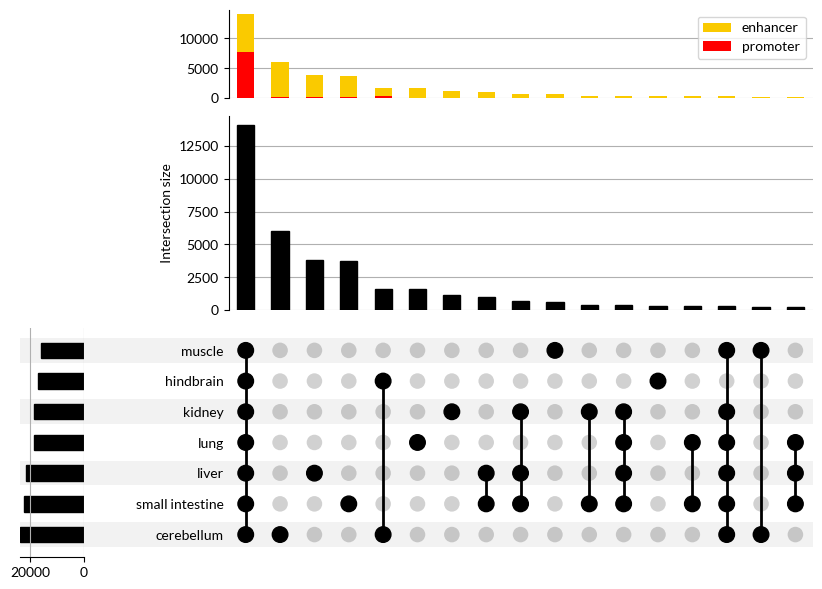

In [10]:
col_count = activity_count_ss.shape[1] - 5
upset_df = from_indicators(activity_count_ss.columns[0:col_count], data=activity_count_ss)
upset = UpSet(upset_df, sort_by = "cardinality", min_subset_size=200)
upset.add_stacked_bars(by = 'feature_type', colors={"promoter": "#ff0000", "enhancer": "#faca00"})
upset.plot()
plt.savefig("exports/pig_upset.svg")

### List of cerebellum-specific regulatory features

In [11]:
# Find features that are expressed specifically in cerebellum
check_results = upset_df.loc[upset_df['cerebellum'] & ~upset_df['small intestine'] & ~upset_df['muscle'] & ~upset_df['hindbrain'] & ~upset_df['kidney'] & ~upset_df['liver'] & ~upset_df['lung']]
check_results

cerebellum  \
cerebellum hindbrain kidney liver lung  muscle small intestine               
True       False     False  False False False  False                  True   
                                               False                  True   
                                               False                  True   
                                               False                  True   
                                               False                  True   
...                                                                    ...   
                                               False                  True   
                                               False                  True   
                                               False                  True   
                                               False                  True   
                                               False                  True   

                                                                hindbrain  \
cerebellum hindbrain kidney liver lung  muscle small intestine              
True       False     False  False False False  False                False   
                                               False                False   
                                               False                False   
                                               False                False   
                                               False                False   
...                                                                   ...   
                                               False                False   
                                               False                False   
                                               False                False   
                                               False                False   
                                               False                False   

                                                                kidney  liver  \
cerebellum hindbrain kidney liver lung  muscle small intestine                  
True       False     False  False False False  False             False  False   
                                               False             False  False   
                                               False             False  False   
                                               False             False  False   
                                               False             False  False   
...                                                                ...    ...   
                                               False             False  False   
                                               False             False  False   
                                               False             False  False   
                                               False             False  False   
                                               False             False  False   

                                                                 lung  muscle  \
cerebellum hindbrain kidney liver lung  muscle small intestine                  
True       False     False  False False False  False            False   False   
                                               False            False   False   
                                               False            False   False   
                                               False            False   False   
                                               False            False   False   
...                                                               ...     ...   
                                               False            False   False   
                                               False            False   False   
                                               False            False   False   
                                               False            False   False   
                     